## C03A – Top 10 đối tác xuất khẩu năm 2024

- **Câu hỏi phụ** - Q2.1.
- **Task** - Xếp hạng 10 đối tác xuất khẩu lớn nhất năm 2024.
- **Dạng** - Thanh ngang xếp hạng.
- **Lý do** - Thanh ngang dễ đọc tên đối tác và so sánh kim ngạch theo thứ hạng.
- **Nguồn** - `data/clean/partner_year.csv`.

In [1]:
import pandas as pd

def lay_du_lieu_c03a(path, year, flow, top_n):
    """Lọc đối tác, tính tỷ trọng trên toàn bộ đối tác hợp lệ rồi lấy Top N."""
    data = pd.read_csv(path, dtype={"partner_iso3": "string"})
    valid = data["partner_iso3"].notna() & ~data["partner_iso3"].isin(["S19", "WLD"])
    selected = data.loc[data["year"].eq(year) & data["trade_flow"].eq(flow) & valid]
    partners = (selected.groupby("partner_iso3", as_index=False)
                .agg(partner_name=("partner_name", "first"),
                     trade_usd=("trade_usd", "sum"))
                .sort_values(["trade_usd", "partner_iso3"], ascending=[False, True]))
    total = partners["trade_usd"].sum()
    if total <= 0 or not 1 <= top_n <= len(partners):
        raise ValueError("Kiểm tra lại năm, chiều thương mại hoặc Top N.")
    partners["trade_billion_usd"] = partners["trade_usd"] / 1e9
    partners["share_pct"] = 100 * partners["trade_usd"] / total
    return partners.head(top_n).reset_index(drop=True)

In [2]:
import matplotlib.pyplot as plt

def ve_c03a(data, year, flow, color):
    """Vẽ thanh ngang từ 0 và tạo action title từ đối tác dẫn đầu."""
    label, verb = {"Export": ("xuất khẩu", "nhận"), "Import": ("nhập khẩu", "cung cấp")}[flow]
    names = {"USA": "Hoa Kỳ", "CHN": "Trung Quốc", "KOR": "Hàn Quốc", "JPN": "Nhật Bản",
             "HKG": "Hồng Kông", "DEU": "Đức", "MEX": "Mexico", "GBR": "Anh",
             "IND": "Ấn Độ", "CAN": "Canada", "SGP": "Singapore", "MYS": "Malaysia",
             "THA": "Thái Lan", "IDN": "Indonesia", "AUS": "Úc"}
    display_names = data["partner_iso3"].map(names).fillna(data["partner_name"])
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.36 * len(data) + 1.6)), layout="constrained")
    # Giữ từng đối tác riêng. Các mã ngoài bảng màu T10 dùng màu bối cảnh.
    colors = data["partner_iso3"].map(hs.PARTNER_COLORS).fillna(hs.OTHER_COLOR) if color is None else color
    bars = ax.barh(display_names, data["trade_billion_usd"], color=colors, height=hs.BAR_WIDTH)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{hs.format_number(v, 1)} ({hs.format_percent(p / 100)})" for v, p in
                               zip(data["trade_billion_usd"], data["share_pct"])], padding=4)
    ax.set(xlim=(0, data["trade_billion_usd"].max() * 1.27), xlabel="Kim ngạch (tỷ USD)")
    ax.set_title(f"{display_names.iloc[0]} {verb} {hs.format_percent(data.iloc[0]['share_pct'] / 100)} tổng {label} năm {year}",
                 loc="center", fontweight="bold")
    hs.declutter(ax, quantitative_axis="x")
    fig.supxlabel("Nguồn: partner_year.csv", x=.99, **(hs.SOURCE | {"ha": "right"}))
    return fig, ax

        partner_name  trade_billion_usd  share_pct
                 USA              140.5       28.2
               China               94.0       18.9
       Rep. of Korea               28.4        5.7
               Japan               26.5        5.3
China, Hong Kong SAR               21.0        4.2
             Germany               15.4        3.1
              Mexico               13.2        2.7
      United Kingdom               10.8        2.2
               India               10.6        2.1
              Canada               10.4        2.1


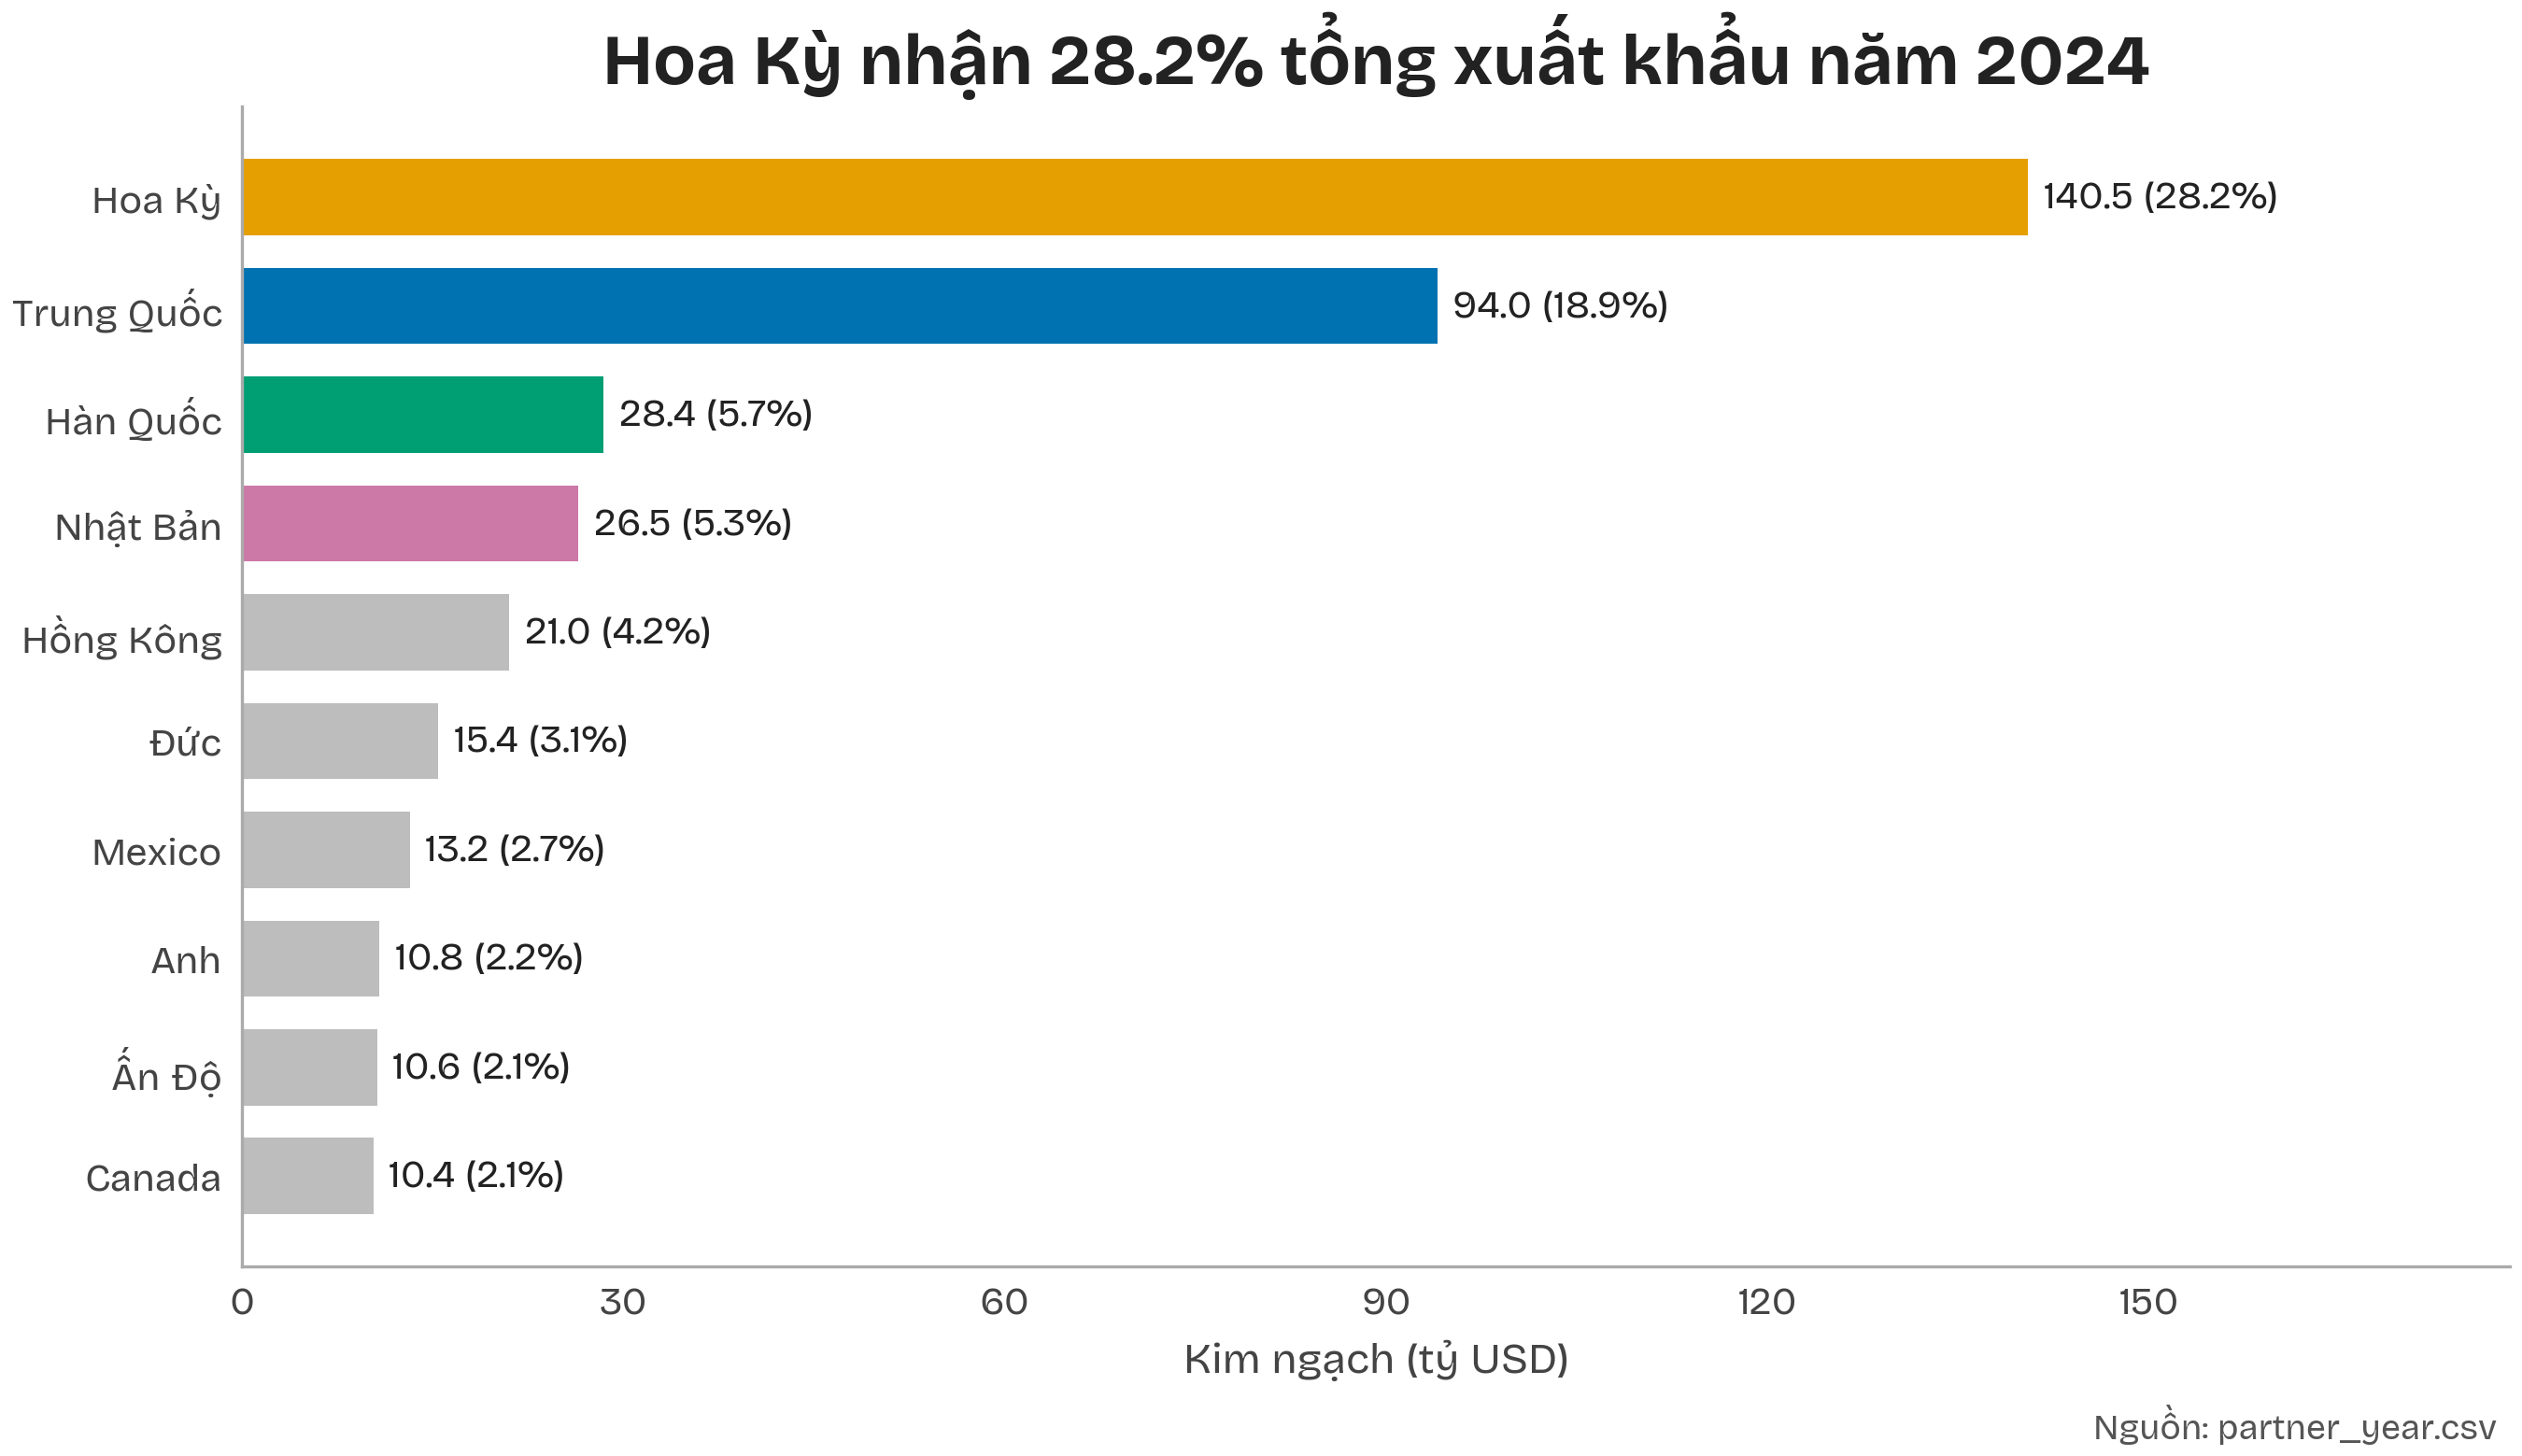

In [3]:
from pathlib import Path
import sys

year_c03a = 2024
flow_c03a = "Export"
top_n_c03a = 10
color_c03a = None  # None dùng màu T10 theo ISO3. Nhập mã hex để đổi sang một màu.

root_c03a = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/clean/partner_year.csv").is_file()),
    Path.cwd(),
)
style_dir_c03a = str(root_c03a / "notebooks")
if style_dir_c03a not in sys.path:
    sys.path.insert(0, style_dir_c03a)
from house_style import house_style as hs

df_c03a = lay_du_lieu_c03a(root_c03a / "data/clean/partner_year.csv",
                                year_c03a, flow_c03a, top_n_c03a)
assert len(df_c03a) == top_n_c03a and df_c03a["trade_usd"].is_monotonic_decreasing
assert df_c03a["share_pct"].sum() <= 100 + 1e-8
print(df_c03a[["partner_name", "trade_billion_usd", "share_pct"]].to_string(index=False, float_format=lambda x: f"{x:.1f}"))
with hs.apply_style():
    fig_c03a, ax_c03a = ve_c03a(df_c03a, year_c03a, flow_c03a, color_c03a)
    output_c03a = root_c03a / f"outputs/core_charts/C03/C03A_{year_c03a}.png"
    output_c03a.parent.mkdir(parents=True, exist_ok=True)
    fig_c03a.savefig(output_c03a, dpi=hs.THEME["savefig.dpi"])
    plt.show()


### Kết luận · C03A

**Action title** - Hoa Kỳ nhận 28.2% tổng xuất khẩu của Việt Nam năm 2024.

Đối tác dẫn đầu đạt **140.5 tỷ USD**. Tỷ trọng tính trên tổng kim ngạch của mọi đối tác hợp lệ trong cùng năm và chiều thương mại. Nhóm gộp Other Asia, nes (S19) được loại khỏi xếp hạng và mẫu số.

## C03B – Top 10 đối tác nhập khẩu năm 2024

- **Câu hỏi phụ** - Q2.1.
- **Task** - Xếp hạng 10 đối tác nhập khẩu lớn nhất năm 2024.
- **Dạng** - Thanh ngang xếp hạng.
- **Lý do** - Thanh ngang dễ đọc tên đối tác và so sánh kim ngạch theo thứ hạng.
- **Nguồn** - `data/clean/partner_year.csv`.

In [4]:
import pandas as pd

def lay_du_lieu_c03b(path, year, flow, top_n):
    """Lọc đối tác, tính tỷ trọng trên toàn bộ đối tác hợp lệ rồi lấy Top N."""
    data = pd.read_csv(path, dtype={"partner_iso3": "string"})
    valid = data["partner_iso3"].notna() & ~data["partner_iso3"].isin(["S19", "WLD"])
    selected = data.loc[data["year"].eq(year) & data["trade_flow"].eq(flow) & valid]
    partners = (selected.groupby("partner_iso3", as_index=False)
                .agg(partner_name=("partner_name", "first"),
                     trade_usd=("trade_usd", "sum"))
                .sort_values(["trade_usd", "partner_iso3"], ascending=[False, True]))
    total = partners["trade_usd"].sum()
    if total <= 0 or not 1 <= top_n <= len(partners):
        raise ValueError("Kiểm tra lại năm, chiều thương mại hoặc Top N.")
    partners["trade_billion_usd"] = partners["trade_usd"] / 1e9
    partners["share_pct"] = 100 * partners["trade_usd"] / total
    return partners.head(top_n).reset_index(drop=True)

In [5]:
import matplotlib.pyplot as plt

def ve_c03b(data, year, flow, color):
    """Vẽ thanh ngang từ 0 và tạo action title từ đối tác dẫn đầu."""
    label, verb = {"Export": ("xuất khẩu", "nhận"), "Import": ("nhập khẩu", "cung cấp")}[flow]
    names = {"USA": "Hoa Kỳ", "CHN": "Trung Quốc", "KOR": "Hàn Quốc", "JPN": "Nhật Bản",
             "HKG": "Hồng Kông", "DEU": "Đức", "MEX": "Mexico", "GBR": "Anh",
             "IND": "Ấn Độ", "CAN": "Canada", "SGP": "Singapore", "MYS": "Malaysia",
             "THA": "Thái Lan", "IDN": "Indonesia", "AUS": "Úc"}
    display_names = data["partner_iso3"].map(names).fillna(data["partner_name"])
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.36 * len(data) + 1.6)), layout="constrained")
    # Giữ từng đối tác riêng. Các mã ngoài bảng màu T10 dùng màu bối cảnh.
    colors = data["partner_iso3"].map(hs.PARTNER_COLORS).fillna(hs.OTHER_COLOR) if color is None else color
    bars = ax.barh(display_names, data["trade_billion_usd"], color=colors, height=hs.BAR_WIDTH)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{hs.format_number(v, 1)} ({hs.format_percent(p / 100)})" for v, p in
                               zip(data["trade_billion_usd"], data["share_pct"])], padding=4)
    ax.set(xlim=(0, data["trade_billion_usd"].max() * 1.27), xlabel="Kim ngạch (tỷ USD)")
    ax.set_title(f"{display_names.iloc[0]} {verb} {hs.format_percent(data.iloc[0]['share_pct'] / 100)} tổng {label} năm {year}",
                 loc="center", fontweight="bold")
    hs.declutter(ax, quantitative_axis="x")
    fig.supxlabel("Nguồn: partner_year.csv", x=.99, **(hs.SOURCE | {"ha": "right"}))
    return fig, ax

        partner_name  trade_billion_usd  share_pct
               China              158.8       43.8
       Rep. of Korea               58.3       16.1
China, Hong Kong SAR               19.7        5.4
           Singapore               17.0        4.7
               Japan               15.9        4.4
                 USA               12.6        3.5
            Malaysia               11.8        3.2
            Thailand               11.8        3.2
           Indonesia                9.5        2.6
           Australia                6.9        1.9


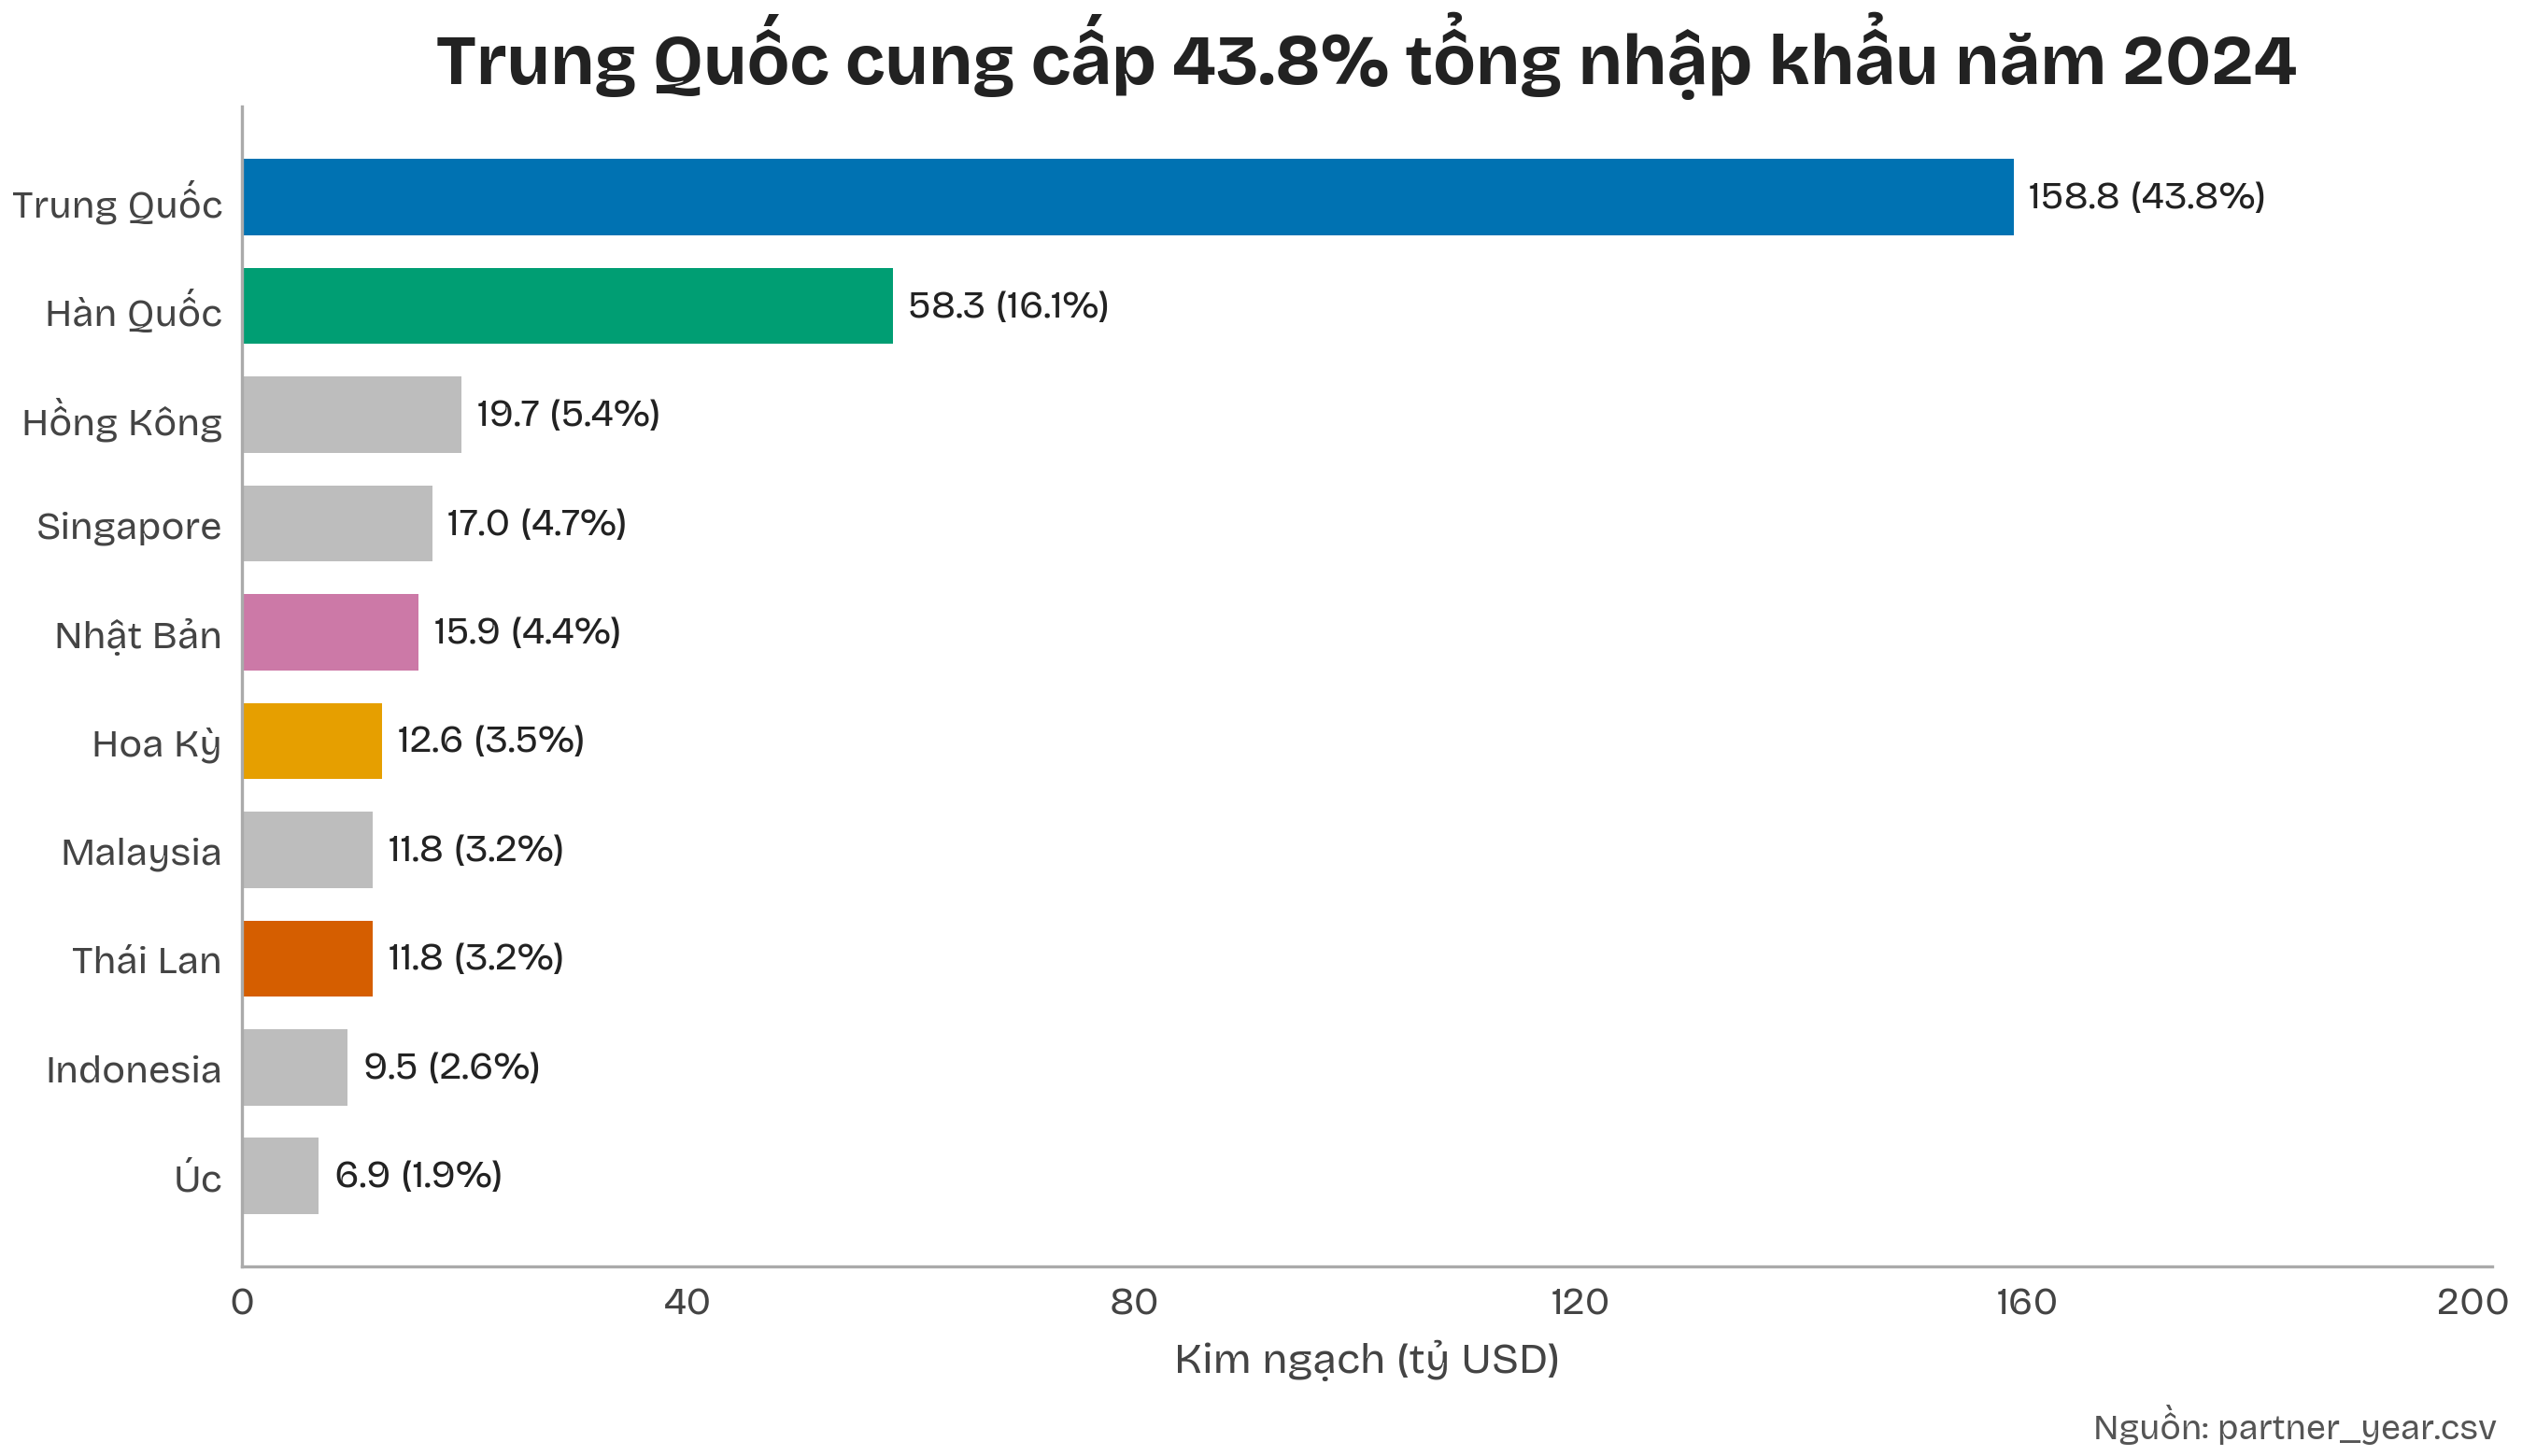

In [6]:
from pathlib import Path
import sys

year_c03b = 2024
flow_c03b = "Import"
top_n_c03b = 10
color_c03b = None  # None dùng màu T10 theo ISO3. Nhập mã hex để đổi sang một màu.

root_c03b = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/clean/partner_year.csv").is_file()),
    Path.cwd(),
)
style_dir_c03b = str(root_c03b / "notebooks")
if style_dir_c03b not in sys.path:
    sys.path.insert(0, style_dir_c03b)
from house_style import house_style as hs

df_c03b = lay_du_lieu_c03b(root_c03b / "data/clean/partner_year.csv",
                                year_c03b, flow_c03b, top_n_c03b)
assert len(df_c03b) == top_n_c03b and df_c03b["trade_usd"].is_monotonic_decreasing
assert df_c03b["share_pct"].sum() <= 100 + 1e-8
print(df_c03b[["partner_name", "trade_billion_usd", "share_pct"]].to_string(index=False, float_format=lambda x: f"{x:.1f}"))
with hs.apply_style():
    fig_c03b, ax_c03b = ve_c03b(df_c03b, year_c03b, flow_c03b, color_c03b)
    output_c03b = root_c03b / f"outputs/core_charts/C03/C03B_{year_c03b}.png"
    output_c03b.parent.mkdir(parents=True, exist_ok=True)
    fig_c03b.savefig(output_c03b, dpi=hs.THEME["savefig.dpi"])
    plt.show()


### Kết luận · C03B

**Action title** - Trung Quốc cung cấp 43.8% tổng nhập khẩu của Việt Nam năm 2024.

Đối tác dẫn đầu đạt **158.8 tỷ USD**. Tỷ trọng tính trên tổng kim ngạch của mọi đối tác hợp lệ trong cùng năm và chiều thương mại. Nhóm gộp Other Asia, nes (S19) được loại khỏi xếp hạng và mẫu số.